# 1. Import thư viện, đọc Train và Validation

In [1]:
from pathlib import Path
import inspect
import json
import shutil
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    precision_recall_fscore_support,
    confusion_matrix
)

# ========================================
# 1. CẤU HÌNH THỰC NGHIỆM E11
# ========================================

EXPERIMENT_ID = "E11"
TARGET = "Attack_type"
RANDOM_STATE = 42
N_SPLITS = 3

# Tìm thư mục gốc IoT_final
CURRENT = Path.cwd().resolve()

ROOT = next(
    (
        p for p in [CURRENT, *CURRENT.parents]
        if (p / "project").is_dir()
        and (p / "result").is_dir()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục IoT_final. "
        "Hãy mở VS Code tại thư mục dự án."
    )

# ========================================
# 2. ĐƯỜNG DẪN TRAIN VÀ VALIDATION ĐÃ CHIA SẴN
# ========================================

DATA_DIR = (
    ROOT / "result"
    / "preprocessing"
    / "E11_MLP_NoScaler_Processing"
    / "data"
)

TRAIN_PATH = DATA_DIR / "train.csv.gz"
VALID_PATH = DATA_DIR / "validation.csv.gz"

# ========================================
# 3. THƯ MỤC KẾT QUẢ E11
# ========================================

RESULT_DIR = (
    ROOT / "result"
    / "exps"
    / "E11_MLP_NoScaler"
)

# Chỉ tạo một folder, không tạo thư mục con
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# ========================================
# 4. ĐỌC DỮ LIỆU
# ========================================

for data_path in [TRAIN_PATH, VALID_PATH]:
    if not data_path.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy dữ liệu: {data_path}"
        )

train_df = pd.read_csv(TRAIN_PATH)
valid_df = pd.read_csv(VALID_PATH)

print("=== THỰC NGHIỆM E11 ===")
print("Mô hình: MLP không sử dụng Scaler")

print("\n=== KÍCH THƯỚC DỮ LIỆU ===")
print("Train:", train_df.shape)
print("Validation:", valid_df.shape)

print("\n=== ĐƯỜNG DẪN KẾT QUẢ ===")
print(RESULT_DIR)

print("\n=== DỮ LIỆU TRAIN ===")
display(train_df.head(3))

=== THỰC NGHIỆM E11 ===
Mô hình: MLP không sử dụng Scaler

=== KÍCH THƯỚC DỮ LIỆU ===
Train: (82536, 83)
Validation: (17686, 83)

=== ĐƯỜNG DẪN KẾT QUẢ ===
D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\exps\E11_MLP_NoScaler

=== DỮ LIỆU TRAIN ===


,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,64177,46532,udp,-,0.000000,1,0,1,0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,NMAP_UDP_SCAN
1,20209,21,tcp,-,0.000005,1,1,1,0,199728.761905,...,0.0,0.0,0.0,0.0,0.0,0.0,64,0,64,DOS_SYN_Hping
2,3694,21,tcp,-,0.000005,1,1,1,0,199728.761905,...,0.0,0.0,0.0,0.0,0.0,0.0,64,0,64,DOS_SYN_Hping


### Chuẩn bị dữ liệu thực nghiệm E11

Chạy notebook `E11_MLP_NoScaler_Processing.ipynb` trước. Notebook này đọc các tập đã chia sẵn trong `splitted data`, giữ nguyên đặc trưng số và xuất dữ liệu riêng cho E11.

E11 không dùng StandardScaler. Các cột `proto` và `service` được OneHotEncoder xử lý bên trong Pipeline của thực nghiệm, fit riêng trong mỗi fold để tránh rò rỉ dữ liệu.


# 2. Xây dựng Pipeline MLP không dùng Scaler

In [2]:
# ========================================
# 1. TÁCH ĐẶC TRƯNG VÀ NHÃN
# ========================================

DROP_COLS = [
    TARGET,
    "Unnamed: 0",
    "group_id"
]

CATEGORICAL_FEATURES = [
    "proto",
    "service"
]

if (
    TARGET not in train_df.columns
    or TARGET not in valid_df.columns
):
    raise ValueError(
        f"Thiếu cột nhãn {TARGET}"
    )

if (
    train_df[TARGET].isna().any()
    or valid_df[TARGET].isna().any()
):
    raise ValueError("Nhãn có giá trị thiếu")

X = train_df.drop(
    columns=DROP_COLS,
    errors="ignore"
).copy()

y = train_df[TARGET].astype(str).copy()

X_valid = valid_df.drop(
    columns=DROP_COLS,
    errors="ignore"
).copy()

y_valid = valid_df[TARGET].astype(str).copy()

# Đồng bộ các cột giữa Train và Validation
if set(X.columns) != set(X_valid.columns):
    raise ValueError(
        "Train và Validation không có cùng tập đặc trưng"
    )

X_valid = X_valid[X.columns]

# ========================================
# 2. PHÂN LOẠI ĐẶC TRƯNG
# ========================================

missing_categories = [
    c for c in CATEGORICAL_FEATURES
    if c not in X.columns
]

if missing_categories:
    raise ValueError(
        f"Thiếu cột categorical: {missing_categories}"
    )

NUMERIC_FEATURES = X.select_dtypes(
    include=np.number
).columns.tolist()

unknown_features = sorted(
    set(X.columns)
    - set(NUMERIC_FEATURES)
    - set(CATEGORICAL_FEATURES)
)

if unknown_features:
    raise ValueError(
        f"Các cột chưa được xử lý: {unknown_features}"
    )

# ========================================
# 3. KIỂM TRA DỮ LIỆU
# ========================================

if X.isna().any().any() or X_valid.isna().any().any():
    raise ValueError(
        "Dữ liệu có NaN. Cần kiểm tra các tập đã chia sẵn."
    )

if not np.isfinite(
    X[NUMERIC_FEATURES].to_numpy(dtype=float)
).all():
    raise ValueError("Train có giá trị vô hạn")

if not np.isfinite(
    X_valid[NUMERIC_FEATURES].to_numpy(dtype=float)
).all():
    raise ValueError("Validation có giá trị vô hạn")

LABELS = sorted(y.unique().tolist())

if not set(y_valid.unique()).issubset(set(LABELS)):
    raise ValueError(
        "Validation có nhãn không tồn tại trong Train"
    )

if y.value_counts().min() < N_SPLITS:
    raise ValueError(
        "Mỗi lớp cần ít nhất 3 mẫu để chia 3-fold"
    )

# ========================================
# 4. HÀM TẠO PIPELINE E11
# ========================================

def make_e11_pipeline():

    # Tương thích nhiều phiên bản sklearn
    ohe_args = {
        "handle_unknown": "ignore"
    }

    if "sparse_output" in inspect.signature(
        OneHotEncoder
    ).parameters:
        ohe_args["sparse_output"] = False
    else:
        ohe_args["sparse"] = False

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                "passthrough",
                NUMERIC_FEATURES
            ),
            (
                "categorical",
                OneHotEncoder(**ohe_args),
                CATEGORICAL_FEATURES
            )
        ],
        remainder="drop",
        sparse_threshold=0
    )

    mlp = MLPClassifier(
        hidden_layer_sizes=(64,),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        learning_rate_init=0.001,
        batch_size=512,
        max_iter=60,
        n_iter_no_change=8,
        early_stopping=False,
        random_state=RANDOM_STATE,
        verbose=False
    )

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", mlp)
    ])

# ========================================
# 5. HÀM ĐÁNH GIÁ MÔ HÌNH
# ========================================

METRICS = [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "macro_precision",
    "macro_recall"
]

def evaluate(y_true, y_pred):

    return {
        "accuracy": accuracy_score(
            y_true, y_pred
        ),

        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),

        "weighted_f1": f1_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="weighted",
            zero_division=0
        ),

        "macro_precision": precision_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),

        "macro_recall": recall_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        )
    }

# ========================================
# 6. KIỂM TRA PIPELINE
# ========================================

print("=== THÔNG TIN E11 ===")
print("Số mẫu Train:", len(X))
print("Số mẫu Validation:", len(X_valid))
print("Số lớp:", len(LABELS))
print("Số đặc trưng số:", len(NUMERIC_FEATURES))
print("Đặc trưng phân loại:", CATEGORICAL_FEATURES)

print("\n=== PIPELINE E11 ===")
print(make_e11_pipeline())

print("\n=== PHÂN BỐ NHÃN TRAIN ===")
display(y.value_counts())

=== THÔNG TIN E11 ===
Số mẫu Train: 82536
Số mẫu Validation: 17686
Số lớp: 12
Số đặc trưng số: 80
Đặc trưng phân loại: ['proto', 'service']

=== PIPELINE E11 ===


Pipeline(steps=[('preprocess',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('numeric', 'passthrough',
                                                  ['id.orig_p', 'id.resp_p',
                                                   'flow_duration',
                                                   'fwd_pkts_tot',
                                                   'bwd_pkts_tot',
                                                   'fwd_data_pkts_tot',
                                                   'bwd_data_pkts_tot',
                                                   'fwd_pkts_per_sec',
                                                   'bwd_pkts_per_sec',
                                                   'flow_pkts_per_sec',
                                                   'down_up_ratio',
                                                   'fwd_header_size_tot',
                                                   'fwd_hea

Attack_type
DOS_SYN_Hping                 63062
Thing_Speak                    5355
ARP_poisioning                 5334
MQTT_Publish                   2899
NMAP_UDP_SCAN                  1807
NMAP_XMAS_TREE_SCAN            1407
NMAP_OS_DETECTION              1400
NMAP_TCP_scan                   701
DDOS_Slowloris                  373
Wipro_bulb                      153
Metasploit_Brute_Force_SSH       25
NMAP_FIN_SCAN                    20
Name: count, dtype: int64

### Tiền xử lý thực nghiệm E11

- Đặc trưng số được giữ nguyên, không chuẩn hóa.
- `proto` và `service` được OneHotEncoder mã hóa trong Pipeline.
- Bộ mã hóa được fit riêng theo từng fold Cross-Validation.


# 3. Huấn luyện 3-ford Cross-Validation

In [3]:
# ========================================
# 3-FOLD CROSS-VALIDATION
# ========================================

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

fold_rows = []
per_class_rows = []
loss_curves = {}

for fold, (fit_idx, cv_idx) in enumerate(
    cv.split(X, y),
    start=1
):

    print("\n" + "=" * 55)
    print(f"E11 - FOLD {fold}/{N_SPLITS}")
    print("=" * 55)

    # Dữ liệu huấn luyện của fold
    X_fit = X.iloc[fit_idx]
    y_fit = y.iloc[fit_idx]

    # Dữ liệu kiểm định của fold
    X_cv = X.iloc[cv_idx]
    y_cv = y.iloc[cv_idx]

    # Khởi tạo mô hình mới
    fold_pipeline = make_e11_pipeline()

    start_time = time.perf_counter()

    # Huấn luyện
    fold_pipeline.fit(X_fit, y_fit)

    elapsed = time.perf_counter() - start_time

    # Dự đoán
    pred_cv = fold_pipeline.predict(X_cv)
    pred_train = fold_pipeline.predict(X_fit)

    # Tính các chỉ số
    cv_scores = evaluate(y_cv, pred_cv)
    train_scores = evaluate(y_fit, pred_train)

    trained_mlp = fold_pipeline.named_steps["model"]

    # Lưu Training Loss
    loss_curves[fold] = list(
        trained_mlp.loss_curve_
    )

    # Lưu kết quả fold
    fold_rows.append({
        "fold": fold,
        "n_train": len(X_fit),
        "n_cv": len(X_cv),
        "epochs": int(trained_mlp.n_iter_),
        "training_time_sec": float(elapsed),
        "final_train_loss": float(trained_mlp.loss_),

        **cv_scores,

        **{
            f"train_{m}": train_scores[m]
            for m in METRICS
        }
    })

    # Tính kết quả từng lớp
    p, r, f, support = (
        precision_recall_fscore_support(
            y_cv,
            pred_cv,
            labels=LABELS,
            zero_division=0
        )
    )

    for label, precision, recall, f1_value, n in zip(
        LABELS,
        p,
        r,
        f,
        support
    ):

        per_class_rows.append({
            "fold": fold,
            "class": label,
            "precision": float(precision),
            "recall": float(recall),
            "f1": float(f1_value),
            "support": int(n)
        })

    print("Số mẫu Train:", len(X_fit))
    print("Số mẫu CV:", len(X_cv))
    print("Số epoch:", trained_mlp.n_iter_)
    print(f"Thời gian: {elapsed:.2f} giây")

    print("\n=== CHỈ SỐ ĐÁNH GIÁ ===")

    for metric in METRICS:
        print(
            f"{metric:18s}: {cv_scores[metric]:.6f}"
        )

# ========================================
# TỔNG HỢP KẾT QUẢ
# ========================================

cv_results = pd.DataFrame(fold_rows)

cv_per_class = pd.DataFrame(per_class_rows)

cv_summary = pd.DataFrame({
    "metric": METRICS,

    "mean": [
        float(cv_results[m].mean())
        for m in METRICS
    ],

    "std": [
        float(cv_results[m].std(ddof=1))
        for m in METRICS
    ]
})

cv_per_class_summary = (
    cv_per_class
    .groupby("class", as_index=False)
    .agg(
        precision_mean=("precision", "mean"),
        recall_mean=("recall", "mean"),
        f1_mean=("f1", "mean"),
        support_total=("support", "sum")
    )
    .sort_values("f1_mean")
)

print("\n=== KẾT QUẢ 3 FOLD ===")

display(
    cv_results[
        [
            "fold",
            *METRICS,
            "epochs",
            "training_time_sec"
        ]
    ].round(6)
)

print("\n=== TRUNG BÌNH 3 FOLD ===")

display(cv_summary.round(6))

print("\n=== CÁC LỚP CÓ F1 THẤP ===")

display(
    cv_per_class_summary.head(5).round(6)
)

# ========================================
# LƯU KẾT QUẢ VÀO FOLDER E11
# ========================================

cv_results.to_csv(
    RESULT_DIR / "E11_cv_folds.csv",
    index=False,
    encoding="utf-8-sig"
)

cv_summary.to_csv(
    RESULT_DIR / "E11_cv_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

cv_per_class.to_csv(
    RESULT_DIR / "E11_cv_per_class.csv",
    index=False,
    encoding="utf-8-sig"
)

cv_per_class_summary.to_csv(
    RESULT_DIR / "E11_cv_per_class_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu kết quả 3-fold CV.")


E11 - FOLD 1/3


Số mẫu Train: 55024
Số mẫu CV: 27512
Số epoch: 34
Thời gian: 6.17 giây

=== CHỈ SỐ ĐÁNH GIÁ ===
accuracy          : 0.964452
macro_f1          : 0.681935
weighted_f1       : 0.958976
macro_precision   : 0.726196
macro_recall      : 0.735627

E11 - FOLD 2/3


Số mẫu Train: 55024
Số mẫu CV: 27512
Số epoch: 27
Thời gian: 4.86 giây

=== CHỈ SỐ ĐÁNH GIÁ ===
accuracy          : 0.955837
macro_f1          : 0.603879
weighted_f1       : 0.953949
macro_precision   : 0.670192
macro_recall      : 0.590772

E11 - FOLD 3/3


Số mẫu Train: 55024
Số mẫu CV: 27512
Số epoch: 23
Thời gian: 4.28 giây

=== CHỈ SỐ ĐÁNH GIÁ ===
accuracy          : 0.945260
macro_f1          : 0.573321
weighted_f1       : 0.942611
macro_precision   : 0.593582
macro_recall      : 0.635913

=== KẾT QUẢ 3 FOLD ===


,fold,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,epochs,training_time_sec
0,1,0.964452,0.681935,0.958976,0.726196,0.735627,34,6.171141
1,2,0.955837,0.603879,0.953949,0.670192,0.590772,27,4.864635
2,3,0.945260,0.573321,0.942611,0.593582,0.635913,23,4.282443



=== TRUNG BÌNH 3 FOLD ===


,metric,mean,std
0,accuracy,0.955183,0.009613
1,macro_f1,0.619712,0.056011
2,weighted_f1,0.951845,0.008383
3,macro_precision,0.663323,0.066573
4,macro_recall,0.654104,0.074121



=== CÁC LỚP CÓ F1 THẤP ===


,class,precision_mean,recall_mean,f1_mean,support_total
5,NMAP_FIN_SCAN,0.000000,0.000000,0.000000,20
4,Metasploit_Brute_Force_SSH,0.111111,0.296296,0.161616,25
11,Wipro_bulb,0.344180,0.372549,0.315723,153
6,NMAP_OS_DETECTION,0.562246,0.468485,0.410921,1400
9,NMAP_XMAS_TREE_SCAN,0.613605,0.577825,0.445665,1407



Đã lưu kết quả 3-fold CV.



### Huấn luyện mô hình bằng 3-fold Cross-Validation

**Quy trình:**
- Sử dụng StratifiedKFold với 3 fold.
- Mỗi fold khởi tạo một Pipeline MLP mới.

**Các chỉ số:**
- Accuracy.
- Macro-F1.
- Weighted-F1.
- Macro-Precision.
- Macro-Recall.

**Thông tin bổ sung:**
- Thời gian huấn luyện.
- Số epoch.
- Training Loss.
- F1-score của từng lớp.


# 4. Huấn luyện toàn bộ Train và đánh giá Validation

In [4]:
# ========================================
# HUẤN LUYỆN TRÊN TOÀN BỘ TRAIN
# ========================================

final_model = make_e11_pipeline()

start_time = time.perf_counter()

final_model.fit(X, y)

full_train_time = (
    time.perf_counter() - start_time
)

# Dự đoán
pred_train = final_model.predict(X)
pred_valid = final_model.predict(X_valid)

# Tính chỉ số
train_scores = evaluate(y, pred_train)
valid_scores = evaluate(y_valid, pred_valid)

final_mlp = final_model.named_steps["model"]

print("=== HUẤN LUYỆN FULL TRAIN ===")
print("Số mẫu:", len(X))
print("Số epoch:", final_mlp.n_iter_)
print(f"Thời gian: {full_train_time:.2f} giây")

# ========================================
# BẢNG CHỈ SỐ TRAIN VÀ VALIDATION
# ========================================

validation_metrics = pd.DataFrame({
    "metric": METRICS,

    "train": [
        train_scores[m]
        for m in METRICS
    ],

    "validation": [
        valid_scores[m]
        for m in METRICS
    ]
})

validation_metrics["train_valid_gap"] = (
    validation_metrics["train"]
    - validation_metrics["validation"]
)

print("\n=== TRAIN / VALIDATION ===")

display(validation_metrics.round(6))

# ========================================
# ĐÁNH GIÁ TỪNG LỚP
# ========================================

p, r, f, support = (
    precision_recall_fscore_support(
        y_valid,
        pred_valid,
        labels=LABELS,
        zero_division=0
    )
)

validation_per_class = pd.DataFrame({
    "class": LABELS,
    "precision": p,
    "recall": r,
    "f1": f,
    "support": support
})

print("\n=== F1-SCORE TỪNG LỚP ===")

display(
    validation_per_class
    .sort_values("f1")
    .round(6)
)

# ========================================
# CONFUSION MATRIX
# ========================================

cm = confusion_matrix(
    y_valid,
    pred_valid,
    labels=LABELS
)

cm_df = pd.DataFrame(
    cm,
    index=LABELS,
    columns=LABELS
)

# ========================================
# TỔNG HỢP CV VÀ VALIDATION CỦA E11
# ========================================

cv_vs_validation = (
    cv_summary[
        ["metric", "mean", "std"]
    ]
    .merge(
        validation_metrics[
            ["metric", "validation"]
        ],
        on="metric"
    )
)

cv_vs_validation["validation_minus_cv_mean"] = (
    cv_vs_validation["validation"]
    - cv_vs_validation["mean"]
)

print("\n=== CV / VALIDATION CỦA E11 ===")

display(cv_vs_validation.round(6))

# ========================================
# LƯU CSV
# ========================================

validation_metrics.to_csv(
    RESULT_DIR / "E11_validation_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

validation_per_class.to_csv(
    RESULT_DIR / "E11_validation_per_class.csv",
    index=False,
    encoding="utf-8-sig"
)

cm_df.to_csv(
    RESULT_DIR / "E11_validation_confusion_matrix.csv",
    encoding="utf-8-sig"
)

cv_vs_validation.to_csv(
    RESULT_DIR / "E11_cv_vs_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu kết quả Validation.")

=== HUẤN LUYỆN FULL TRAIN ===
Số mẫu: 82536
Số epoch: 40
Thời gian: 11.52 giây

=== TRAIN / VALIDATION ===


,metric,train,validation,train_valid_gap
0,accuracy,0.963168,0.963813,-0.000646
1,macro_f1,0.639594,0.638371,0.001223
2,weighted_f1,0.959734,0.960538,-0.000804
3,macro_precision,0.700862,0.701301,-0.000439
4,macro_recall,0.635970,0.637287,-0.001317



=== F1-SCORE TỪNG LỚP ===


,class,precision,recall,f1,support
5,NMAP_FIN_SCAN,0.000000,0.000000,0.000000,4
4,Metasploit_Brute_Force_SSH,0.000000,0.000000,0.000000,5
9,NMAP_XMAS_TREE_SCAN,0.851351,0.208609,0.335106,302
1,DDOS_Slowloris,0.838710,0.325000,0.468468,80
11,Wipro_bulb,0.486486,0.545455,0.514286,33
6,NMAP_OS_DETECTION,0.549242,0.966667,0.700483,300
0,ARP_poisioning,0.850655,0.852143,0.851399,1143
8,NMAP_UDP_SCAN,0.935860,0.829457,0.879452,387
10,Thing_Speak,0.907873,0.945074,0.926100,1147
7,NMAP_TCP_scan,1.000000,0.986755,0.993333,151



=== CV / VALIDATION CỦA E11 ===


,metric,mean,std,validation,validation_minus_cv_mean
0,accuracy,0.955183,0.009613,0.963813,0.008630
1,macro_f1,0.619712,0.056011,0.638371,0.018659
2,weighted_f1,0.951845,0.008383,0.960538,0.008693
3,macro_precision,0.663323,0.066573,0.701301,0.037977
4,macro_recall,0.654104,0.074121,0.637287,-0.016817



Đã lưu kết quả Validation.



### Huấn luyện toàn bộ Train và đánh giá Validation

**Quy trình:**
- Khởi tạo lại mô hình MLP E11.
- Huấn luyện trên toàn bộ Train.
- Dự đoán trên Validation.
- Tính 5 chỉ số đánh giá.
- Đánh giá Precision, Recall và F1-score của từng lớp.

**Mục tiêu:**

Quan sát khả năng phân loại và mức độ tổng quát hóa của mô hình MLP khi không sử dụng Scaler.


# 5. Vẽ biểu đồ kết quả

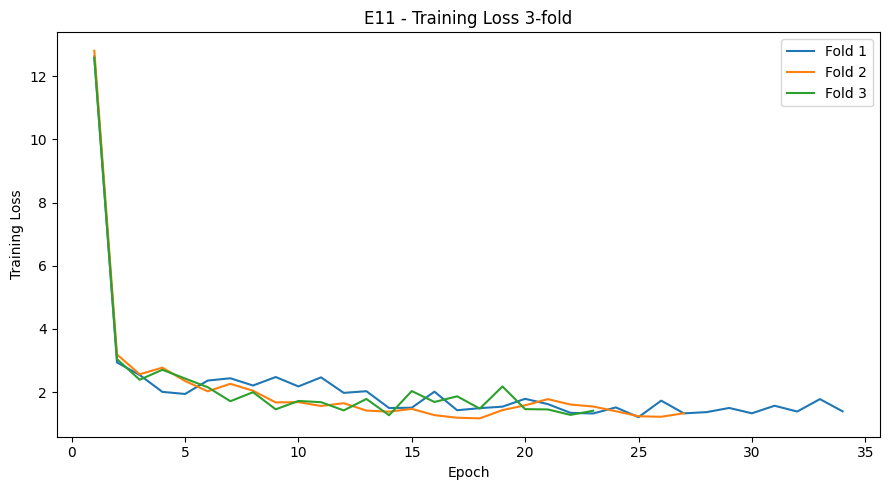

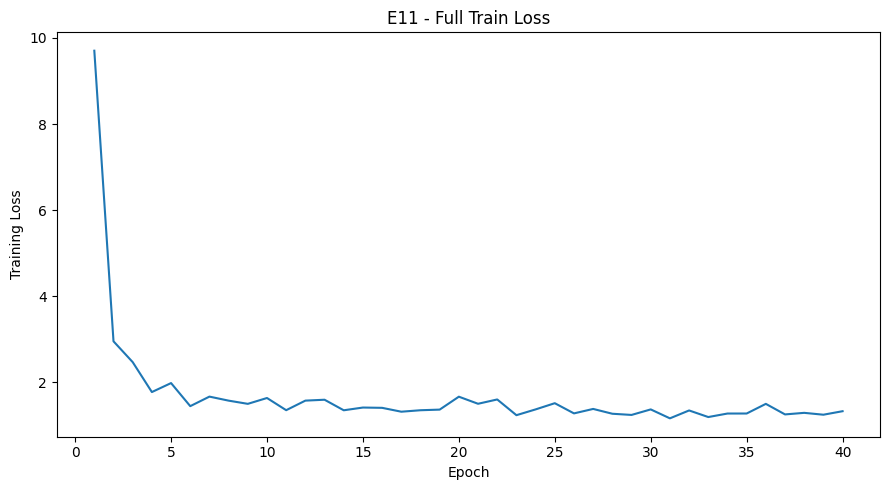

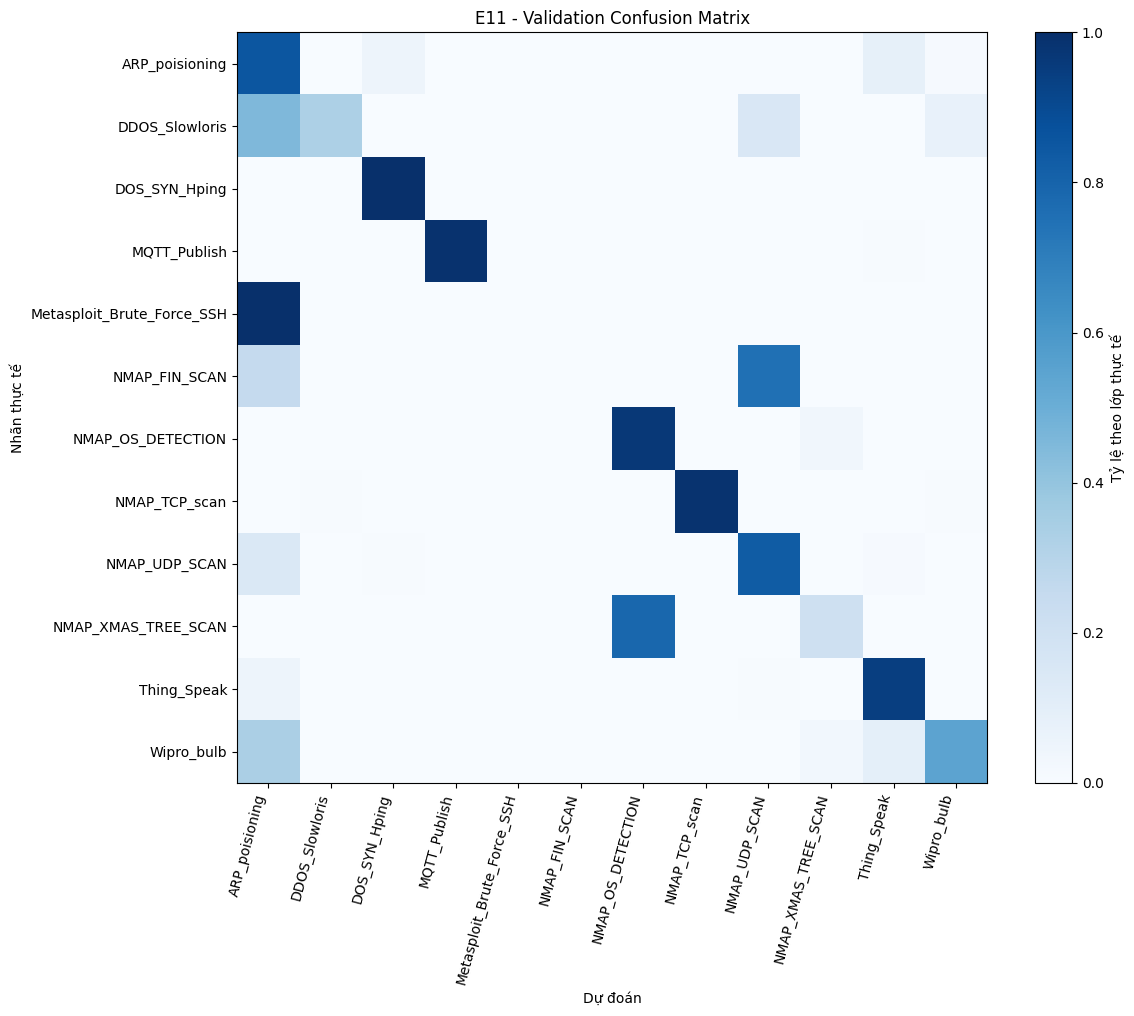

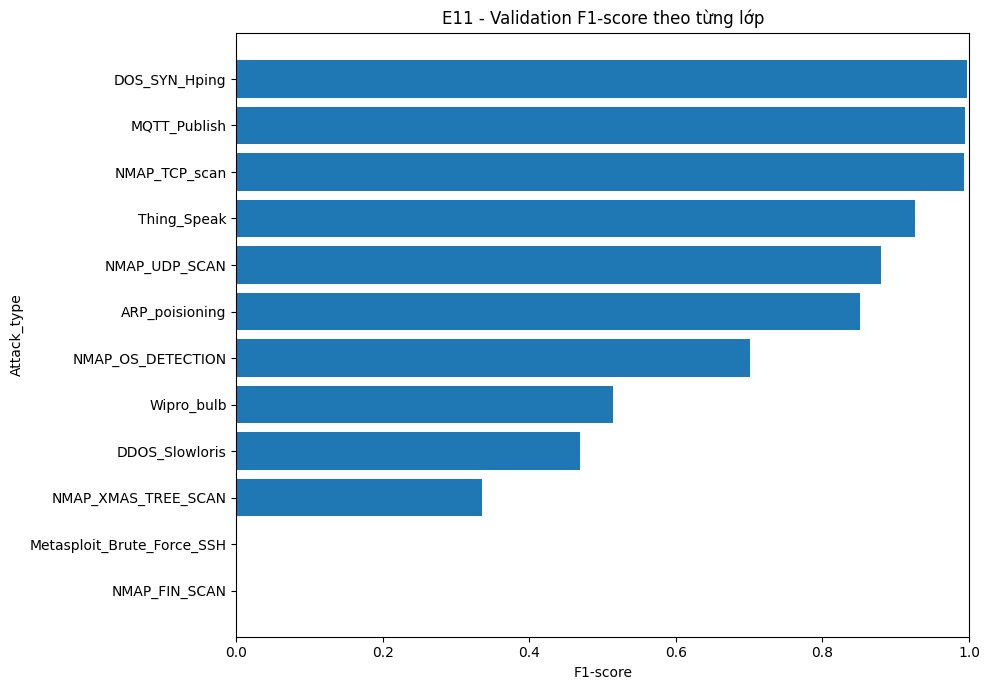

=== ĐÃ LƯU 4 HÌNH PNG ===
D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\exps\E11_MLP_NoScaler


In [5]:
# ========================================
# 5.1. TRAINING LOSS 3 FOLD
# ========================================

fig, ax = plt.subplots(figsize=(9, 5))

for fold, losses in loss_curves.items():

    ax.plot(
        range(1, len(losses) + 1),
        losses,
        label=f"Fold {fold}"
    )

ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss")
ax.set_title("E11 - Training Loss 3-fold")

ax.legend()
fig.tight_layout()

fig.savefig(
    RESULT_DIR / "E11_3fold_training_loss.png",
    dpi=160
)

plt.show()


# ========================================
# 5.2. TRAINING LOSS FULL TRAIN
# ========================================

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    range(1, len(final_mlp.loss_curve_) + 1),
    final_mlp.loss_curve_
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss")
ax.set_title("E11 - Full Train Loss")

fig.tight_layout()

fig.savefig(
    RESULT_DIR / "E11_full_train_loss.png",
    dpi=160
)

plt.show()


# ========================================
# 5.3. CONFUSION MATRIX VALIDATION
# ========================================

row_totals = cm.sum(
    axis=1,
    keepdims=True
)

cm_normalized = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    cm_normalized,
    cmap="Blues",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(LABELS)))
ax.set_yticks(range(len(LABELS)))

ax.set_xticklabels(
    LABELS,
    rotation=75,
    ha="right"
)

ax.set_yticklabels(LABELS)

ax.set_xlabel("Dự đoán")
ax.set_ylabel("Nhãn thực tế")

ax.set_title(
    "E11 - Validation Confusion Matrix"
)

fig.colorbar(
    im,
    ax=ax,
    label="Tỷ lệ theo lớp thực tế"
)

fig.tight_layout()

fig.savefig(
    RESULT_DIR / "E11_validation_confusion_matrix.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# ========================================
# 5.4. F1-SCORE THEO TỪNG LỚP
# ========================================

f1_plot = (
    validation_per_class
    .sort_values("f1")
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    f1_plot["class"],
    f1_plot["f1"]
)

ax.set_xlim(0, 1)

ax.set_xlabel("F1-score")
ax.set_ylabel("Attack_type")
ax.set_title(
    "E11 - Validation F1-score theo từng lớp"
)

fig.tight_layout()

fig.savefig(
    RESULT_DIR / "E11_validation_f1_per_class.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("=== ĐÃ LƯU 4 HÌNH PNG ===")
print(RESULT_DIR)


### Trực quan hóa kết quả thực nghiệm E11

**Các biểu đồ:**
- Training Loss của 3 fold.
- Training Loss trên toàn bộ Train.
- Confusion Matrix trên Validation.
- F1-score theo từng lớp trên Validation.

**Ý nghĩa:**

Training Loss giúp theo dõi quá trình tối ưu của MLP.

Confusion Matrix giúp quan sát các trường hợp phân loại chính xác và nhầm lẫn giữa các nhãn.

Biểu đồ F1-score theo từng lớp giúp xác định những lớp mà mô hình dự đoán chưa tốt.


# 6. Xuất file excel kết quả

In [6]:
from openpyxl import Workbook

from openpyxl.styles import (
    Font,
    Alignment,
    PatternFill,
    Border,
    Side
)

from openpyxl.utils import get_column_letter

# ========================================
# 1. TẠO WORKBOOK
# ========================================

excel_path = (
    RESULT_DIR / "E11_MLP_Exps_KetQua.xlsx"
)

wb = Workbook()
ws = wb.active

ws.title = "E11 No Scaler"

ws.sheet_view.showGridLines = False

# ========================================
# 2. TIÊU ĐỀ
# ========================================

ws.merge_cells("A1:Z1")

ws["A1"] = "MÔ HÌNH: MLP - E11 KHÔNG SCALER"

# ========================================
# 3. NHÓM CỘT
# ========================================

groups = {
    "A2:D2": "Các lượt chạy 3 cross validation",
    "E2:I2": "Lượt 1",
    "J2:N2": "Lượt 2",
    "O2:S2": "Lượt 3",
    "T2:X2": "Valid",
    "Y2:Z2": "Nhận xét"
}

for cell_range, title in groups.items():

    ws.merge_cells(cell_range)

    first_cell = cell_range.split(":")[0]

    ws[first_cell] = title

# ========================================
# 4. TÊN CỘT
# ========================================

headers = (
    [
        "MÃ",
        "MÃ SO SÁNH",
        "Xử lý dữ liệu",
        "Thông số model"
    ]
    + METRICS * 4
    + [
        "Điểm yếu",
        "Đã khắc phục"
    ]
)

for col, header in enumerate(
    headers,
    start=1
):
    ws.cell(
        row=3,
        column=col,
        value=header
    )

# ========================================
# 5. THÔNG TIN E11
# ========================================

ws["A4"] = "E11"
ws["B4"] = "E10"

ws["C4"] = (
    "Không sử dụng Scaler trên nhánh numeric; "
    "OneHotEncoder cho proto và service."
)

ws["D4"] = (
    "MLP (64,), ReLU, Adam; "
    "alpha=0.0001, "
    "learning_rate_init=0.001, "
    "batch_size=512, "
    "max_iter=60, "
    "n_iter_no_change=8, "
    "early_stopping=False, "
    "random_state=42"
)

# ========================================
# 6. GHI KẾT QUẢ 3 FOLD
# ========================================

scores_by_fold = cv_results.set_index("fold")

for fold in [1, 2, 3]:

    first_col = 5 + (fold - 1) * 5

    for idx, metric in enumerate(METRICS):

        score = float(
            scores_by_fold.loc[fold, metric]
        )

        cell = ws.cell(
            row=4,
            column=first_col + idx,
            value=score
        )

        cell.number_format = "0.000000"

# ========================================
# 7. GHI KẾT QUẢ VALIDATION
# ========================================

for idx, metric in enumerate(METRICS):

    score = float(valid_scores[metric])

    cell = ws.cell(
        row=4,
        column=20 + idx,
        value=score
    )

    cell.number_format = "0.000000"

# ========================================
# 8. NHẬN XÉT
# ========================================

ws["Y4"] = (
    "Chưa so sánh với E10; "
    "cần xem các lớp có F1/Recall thấp."
)

ws["Z4"] = (
    "Đã chạy E11 không Scaler; "
    "chưa kết luận hiệu quả cải tiến."
)

# ========================================
# 9. ĐỊNH DẠNG EXCEL
# ========================================

ws["A1"].font = Font(
    name="Calibri",
    size=14,
    bold=True,
    color="16324F"
)

ws["A1"].alignment = Alignment(
    horizontal="center",
    vertical="center"
)

ws.row_dimensions[1].height = 32
ws.row_dimensions[2].height = 26
ws.row_dimensions[3].height = 38
ws.row_dimensions[4].height = 85

# Định dạng hàng 2 và 3
for row_number, fill_color in [
    (2, "DCEAF7"),
    (3, "EAF1F8")
]:

    for row in ws.iter_rows(
        min_row=row_number,
        max_row=row_number,
        min_col=1,
        max_col=26
    ):

        for cell in row:

            cell.fill = PatternFill(
                "solid",
                fgColor=fill_color
            )

            cell.font = Font(
                name="Calibri",
                size=10,
                bold=True,
                color="17324D"
            )

            cell.alignment = Alignment(
                horizontal="center",
                vertical="center",
                wrap_text=True
            )

# Độ rộng các cột
width_by_column = {
    "A": 20,
    "B": 17,
    "C": 41,
    "D": 56,
    "Y": 40,
    "Z": 42
}

for col, width in width_by_column.items():
    ws.column_dimensions[col].width = width

for col in range(5, 25):

    letter = get_column_letter(col)

    ws.column_dimensions[letter].width = 17

# Viền và căn chỉnh
thin = Side(
    style="thin",
    color="C5D1DD"
)

for row in ws.iter_rows(
    min_row=3,
    max_row=4,
    min_col=1,
    max_col=26
):

    for cell in row:

        cell.border = Border(
            left=thin,
            right=thin,
            top=thin,
            bottom=thin
        )

        if cell.row == 4:

            cell.alignment = Alignment(
                horizontal=(
                    "center"
                    if 5 <= cell.column <= 24
                    else "left"
                ),
                vertical="center",
                wrap_text=True
            )

ws.freeze_panes = "E4"

# ========================================
# 10. LƯU FILE EXCEL
# ========================================

wb.save(excel_path)

print("=== ĐÃ XUẤT EXCEL ===")
print(excel_path)

# ========================================
# 11. LƯU CẤU HÌNH E11
# ========================================

config = {
    "experiment": "E11",
    "compare_id": "E10",
    "model": "MLPClassifier",
    "data_source": "result/preprocessing/E11_MLP_NoScaler_Processing/data",
    "preprocessing_notebook": "E11_MLP_NoScaler_Processing.ipynb",
    "train_path": str(TRAIN_PATH),
    "validation_path": str(VALID_PATH),

    "numeric_scaler": "none (passthrough)",
    "categorical_encoder": "OneHotEncoder",

    "hidden_layer_sizes": [64],
    "activation": "relu",
    "solver": "adam",

    "alpha": 0.0001,
    "learning_rate_init": 0.001,
    "batch_size": 512,

    "max_iter": 60,
    "n_iter_no_change": 8,
    "early_stopping": False,

    "random_state": RANDOM_STATE,
    "cv_folds": N_SPLITS,

    "train_samples": int(len(X)),
    "validation_samples": int(len(X_valid)),

    "classes": LABELS,
    "test_used": False,
    "comparison_completed": False
}

with open(
    RESULT_DIR / "E11_config.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        config,
        f,
        indent=2,
        ensure_ascii=False
    )

print("Đã lưu cấu hình E11.")

=== ĐÃ XUẤT EXCEL ===
D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\exps\E11_MLP_NoScaler\E11_MLP_Exps_KetQua.xlsx
Đã lưu cấu hình E11.
